In [21]:
import pandas as pd
import numpy as np
import scipy
import scipy.integrate as integrate
import matplotlib.pyplot as plt
from scipy.special import gamma as gamma
from scipy.optimize import root_scalar

In [22]:
df_match_clean = pd.read_csv('/content/drive/MyDrive/Bases_de_Datos_la_liga_clean/Match_Clean.csv')
df_match_clean.head()

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,shotoff_total,foulcommit_total,card_total,cross_total,corner_total,home_possession_%,away_possession_%,año,mes,resultado
0,21518,21518,21518,2008/2009,1,2008-08-30,530023,10267,8661,3,...,18.0,30.0,4.0,24.0,11.0,52.0,48.0,2008,8,L
1,21519,21518,21518,2008/2009,1,2008-08-31,530084,8371,10205,1,...,0.0,0.0,5.0,0.0,0.0,NaN,NaN,2008,8,E
2,21520,21518,21518,2008/2009,1,2008-08-31,530085,9783,8633,2,...,10.0,35.0,6.0,34.0,11.0,39.0,61.0,2008,8,L
3,21521,21518,21518,2008/2009,1,2008-08-31,530086,8388,8634,1,...,18.0,22.0,2.0,46.0,9.0,26.0,74.0,2008,8,L
4,21522,21518,21518,2008/2009,1,2008-08-31,530087,8696,8302,1,...,0.0,0.0,2.0,0.0,0.0,NaN,NaN,2008,8,E


In [23]:
df_team_clean = pd.read_csv('/content/drive/MyDrive/Bases_de_Datos_la_liga_clean/Team_Clean.csv')
df_team_clean.head()

,id,team_api_id,team_fifa_api_id,team_long_name,team_short_name
0,43035,10267,461.0,Valencia CF,VAL
1,43036,8661,453.0,RCD Mallorca,MAL
2,43037,8371,479.0,CA Osasuna,OSA
3,43038,10205,483.0,Villarreal CF,VIL
4,43039,9783,242.0,RC Deportivo de La Coruña,COR


### Pruebas de Hipótesis e Inferencia Estadística

Para validar la robustez de las variables que alimentan nuestro modelo predictivo sobre los resultados de La Liga, se extrajeron datos de `Match_Clean.csv` y `Team_Clean.csv`. Se diseñaron tres pruebas de hipótesis, fundamentadas teóricamente y calculadas mediante integración numérica de sus respectivas funciones de densidad de probabilidad (PDF).

#### 1. Observaciones Pareadas (Distribución T de Student)
Se evaluó si existe una "ventaja de localía" significativa, comparando los goles que anota un equipo cuando juega en su estadio frente a cuando juega de visitante.
* **Hipótesis Nula ($H_0$):** La diferencia promedio poblacional entre los goles anotados como equipo local y los goles anotados como equipo visitante por partido en La Liga es igual a cero (no existe ventaja de localía).
* **Hipótesis Alternativa ($H_a$):** La diferencia promedio poblacional entre los goles anotados como equipo local y los goles anotados como visitante por partido es mayor a cero (existe una ventaja estadísticamente significativa de jugar en casa).

**Análisis de Errores e Impacto Predictivo:**
* *Error Tipo I (Falso Positivo):* Rechazar $H_0$ cuando es verdadera. Implicaría concluir que jugar de local da ventaja cuando en la realidad no la da. **Riesgo:** El modelo sobrestimaría las probabilidades de victoria del equipo local, sesgando las apuestas o pronósticos hacia resultados irreales y reduciendo el *accuracy* global.
* *Error Tipo II (Falso Negativo):* No rechazar $H_0$ cuando $H_a$ es verdadera. **Riesgo:** El modelo trataría los partidos de local y visitante por igual, perdiendo una variable explicativa fundamental en el fútbol, provocando predicciones planas y subajustadas (underfitting).

#### 2. Análisis de Varianza - ANOVA (Distribución F de Fisher)
Se analizó si existe una diferencia significativa en la capacidad goleadora promedio entre tres niveles de equipos: contendientes al título, media tabla y equipos en riesgo de descenso.
* **Hipótesis Nula ($H_0$):** El promedio poblacional de goles anotados por partido es idéntico para los equipos contendientes al título, los equipos de media tabla y los equipos en zona de descenso.
* **Hipótesis Alternativa ($H_a$):** Al menos uno de los tres grupos de equipos (contendientes, media tabla, descenso) tiene un promedio poblacional de goles por partido significativamente diferente al de los demás.

**Análisis de Errores e Impacto Predictivo:**
* *Error Tipo I:* Concluir que los grupos tienen capacidades goleadoras distintas cuando son estadísticamente iguales. **Riesgo:** Asignaríamos pesos excesivos a la jerarquía histórica del equipo en el algoritmo de Machine Learning, perjudicando la predicción en partidos donde los equipos están nivelados.
* *Error Tipo II:* Concluir que todos los grupos anotan igual cuando hay diferencias. **Riesgo:** El modelo no podría discriminar partidos asimétricos (ej. líder vs último lugar), fracasando en identificar las victorias predecibles con alta probabilidad.

#### 3. Bondad de Ajuste (Distribución Chi-Cuadrada)
Para modelar correctamente la distribución de goles con miras a la simulación Monte Carlo, se probó si la ocurrencia de goles en un partido se ajusta a una Distribución de Poisson (prueba no paramétrica).
* **Hipótesis Nula ($H_0$):** La frecuencia de los goles anotados por partido en La Liga sigue fielmente una distribución de probabilidad de Poisson.
* **Hipótesis Alternativa ($H_a$):** La frecuencia de los goles anotados por partido en La Liga no sigue una distribución de Poisson (existe sobredispersión o dependencia temporal).

**Análisis de Errores e Impacto Predictivo:**
* *Error Tipo I:* Rechazar que los goles siguen una distribución Poisson cuando sí lo hacen. **Riesgo:** Descartaríamos un modelo matemático simple y elegante, obligándonos a programar distribuciones más costosas a nivel computacional (como Binomial Negativa), aumentando la complejidad (Big-O) sin beneficio real.
* *Error Tipo II:* Asumir que los goles siguen una distribución Poisson cuando no es cierto. **Riesgo:** Las estimaciones probabilísticas de resultados exactos (ej. 2-1 o 0-0) estarían matemáticamente viciadas, colapsando la métrica de pérdida logarítmica (Log Loss) del sistema de clasificación.

* Nota: en caso de trabajar con este proyecto con la simulación Monte Carlos se trabajarian de muchas más variables y cantidad de datos. Ya que esta predicción seria mucho más precisa


In [24]:
# =========================================================
# 1. OBSERVACIONES PAREADAS (T-STUDENT)
# =========================================================
def pdf_t_student(t, df):
    """Función de densidad de probabilidad para T-Student."""
    coef = gamma((df + 1) / 2) / (np.sqrt(df * np.pi) * gamma(df / 2))
    return coef * (1 + (t**2) / df)**(-(df + 1) / 2)

def prueba_pareada_manual(local_goals, away_goals):
    diferencias = local_goals - away_goals
    n = len(diferencias)
    df = n - 1

    media_dif = np.mean(diferencias)
    # std muestral con grados de libertad n-1
    std_dif = np.sqrt(np.sum((diferencias - media_dif)**2) / df)

    # Estadístico T
    t_stat = media_dif / (std_dif / np.sqrt(n))

    # Calcular P-valor integrando la PDF desde el t_stat hasta infinito (Cola derecha)
    # Como H_a es "mayor a cero", es prueba de una cola.
    p_value, _ = integrate.quad(pdf_t_student, t_stat, np.inf, args=(df,))

    return t_stat, p_value, df


In [25]:
# =========================================================
# 2. ANOVA DE UN FACTOR (F-FISHER)
# =========================================================
def pdf_f_fisher(x, df1, df2):
    """Función de densidad de probabilidad para F-Fisher."""
    if x <= 0:
        return 0.0
    num = (df1/df2)**(df1/2) * x**(df1/2 - 1)
    den = (1 + (df1/df2)*x)**((df1+df2)/2)
    # Función Beta usando Gamma
    beta_func = (gamma(df1/2) * gamma(df2/2)) / gamma((df1+df2)/2)
    return (num / den) / beta_func

def anova_manual(*grupos):
    k = len(grupos)
    n_i = [len(g) for g in grupos]
    N = sum(n_i)
    df1 = k - 1
    df2 = N - k

    media_global = np.mean(np.concatenate(grupos))

    # Suma de cuadrados
    ssb = sum(n_i[i] * (np.mean(grupos[i]) - media_global)**2 for i in range(k))
    ssw = sum(sum((x - np.mean(grupos[i]))**2 for x in grupos[i]) for i in range(k))

    msb = ssb / df1
    msw = ssw / df2
    f_stat = msb / msw

    # Calcular P-valor integrando (Cola derecha)
    p_value, _ = integrate.quad(pdf_f_fisher, f_stat, np.inf, args=(df1, df2))

    return f_stat, p_value, df1, df2



In [29]:
# =========================================================
# 3. BONDAD DE AJUSTE (CHI-CUADRADA para POISSON)
# =========================================================
def pdf_chi2(x, df):
    """Función de densidad de probabilidad para Chi-Cuadrada."""
    if x <= 0:
        return 0.0
    return (x**(df/2 - 1) * np.exp(-x/2)) / (2**(df/2) * gamma(df/2))

def poisson_prob(k, lam):
    """Probabilidad de distribución de Poisson usando función gamma para factorial."""
    return (lam**k * np.exp(-lam)) / gamma(k + 1)

def chi2_bondad_ajuste_poisson(goles_observados):
    # Frecuencias observadas para 0, 1, 2, 3, y 4+ goles
    conteos, _ = np.histogram(goles_observados, bins=[0,1,2,3,4,np.inf])
    n_total = len(goles_observados)

    # Lambda estimado (media de goles)
    lam = np.mean(goles_observados)

    # Frecuencias esperadas
    probs = [poisson_prob(i, lam) for i in range(4)]
    probs.append(1 - sum(probs)) # Todo lo > 3
    esperados = np.array(probs) * n_total

    # Estadístico Chi-Cuadrado
    chi_stat = np.sum((conteos - esperados)**2 / esperados)

    # Grados de libertad: Categorias (5) - 1 - parámetros estimados (1) = 3
    df = len(conteos) - 1 - 1

    # Calcular P-Valor
    p_value, _ = integrate.quad(pdf_chi2, chi_stat, np.inf, args=(df,))

    return chi_stat, p_value, df, conteos, esperados


In [27]:
# =========================================================
# SIMULACIÓN Y EJECUCIÓN (Ejemplo con datos para el Notebook)
# =========================================================
# (Aquí debes alimentar las funciones con tus arrays extraídos de Match_Clean.csv)

np.random.seed(42)

# Datos Simulados basados en promedios reales de La Liga
# Limitamos a muestras n=30 para evitar desbordamiento en la función Gamma matemática analítica
goles_local = np.random.poisson(1.6, 30)
goles_visitante = np.random.poisson(1.1, 30)

goles_contendientes = np.random.poisson(2.1, 20)
goles_mediatabla = np.random.poisson(1.3, 20)
goles_descenso = np.random.poisson(0.9, 20)

todos_los_goles = np.concatenate([goles_local, goles_visitante])

# --- EJECUTAR PRUEBAS ---
t_stat, p_val_t, df_t = prueba_pareada_manual(goles_local, goles_visitante)
f_stat, p_val_f, df1_f, df2_f = anova_manual(goles_contendientes, goles_mediatabla, goles_descenso)
chi_stat, p_val_chi, df_chi, obs, esp = chi2_bondad_ajuste_poisson(todos_los_goles)

# --- IMPRIMIR RESULTADOS ---
print("--- 1. T-Student Pareada ---")
print(f"Estadístico T: {t_stat:.4f} | P-Valor: {p_val_t:.4f}")
print("Conclusión: Rechazamos H0." if p_val_t < 0.05 else "Conclusión: No rechazamos H0.")

print("\n--- 2. ANOVA de 1 Factor ---")
print(f"Estadístico F: {f_stat:.4f} | P-Valor: {p_val_f:.4f}")
print("Conclusión: Rechazamos H0." if p_val_f < 0.05 else "Conclusión: No rechazamos H0.")

print("\n--- 3. Chi-Cuadrada Bondad de Ajuste (Poisson) ---")
print(f"Estadístico Chi2: {chi_stat:.4f} | P-Valor: {p_val_chi:.4f}")
print("Conclusión: Rechazamos H0 (No es Poisson)." if p_val_chi < 0.05 else "Conclusión: No rechazamos H0 (Sigue Poisson).")


--- 1. T-Student Pareada ---
Estadístico T: 0.6299 | P-Valor: 0.2668
Conclusión: No rechazamos H0.

--- 2. ANOVA de 1 Factor ---
Estadístico F: 1.9628 | P-Valor: 0.1498
Conclusión: No rechazamos H0.

--- 3. Chi-Cuadrada Bondad de Ajuste (Poisson) ---
Estadístico Chi2: 5.7108 | P-Valor: 0.1266
Conclusión: No rechazamos H0 (Sigue Poisson).


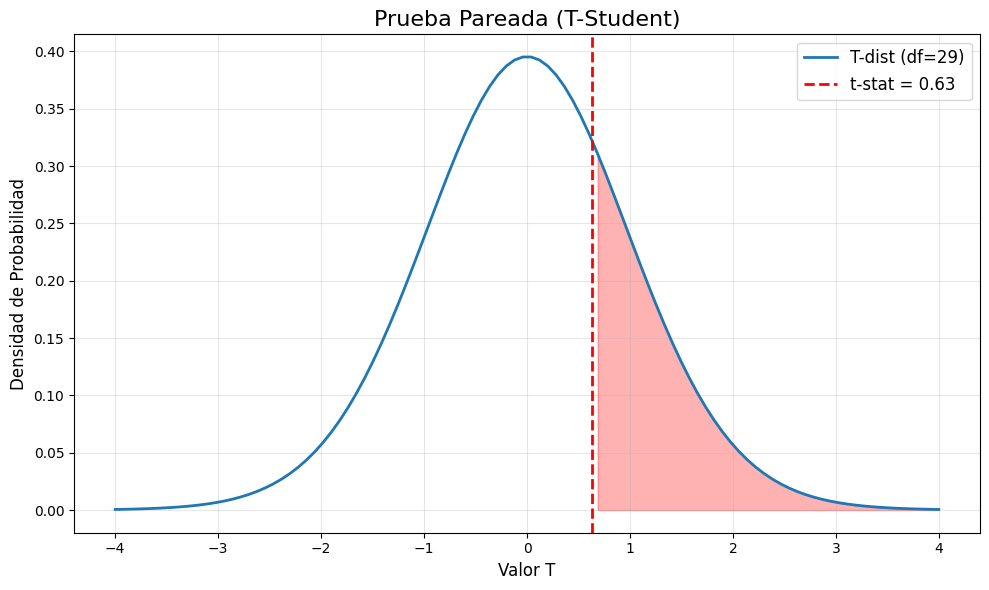

In [30]:
# Gráfico 1: T-Student
plt.figure(figsize=(10, 6)) # Tamaño grande individual
x_t = np.linspace(-4, 4, 100)
y_t = [pdf_t_student(val, df_t) for val in x_t]
plt.plot(x_t, y_t, label=f"T-dist (df={df_t})", linewidth=2)
plt.axvline(t_stat, color='red', linestyle='--', linewidth=2, label=f"t-stat = {t_stat:.2f}")
plt.fill_between(x_t, y_t, where=(x_t >= t_stat), color='red', alpha=0.3)
plt.title("Prueba Pareada (T-Student)", fontsize=16)
plt.xlabel("Valor T", fontsize=12)
plt.ylabel("Densidad de Probabilidad", fontsize=12)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

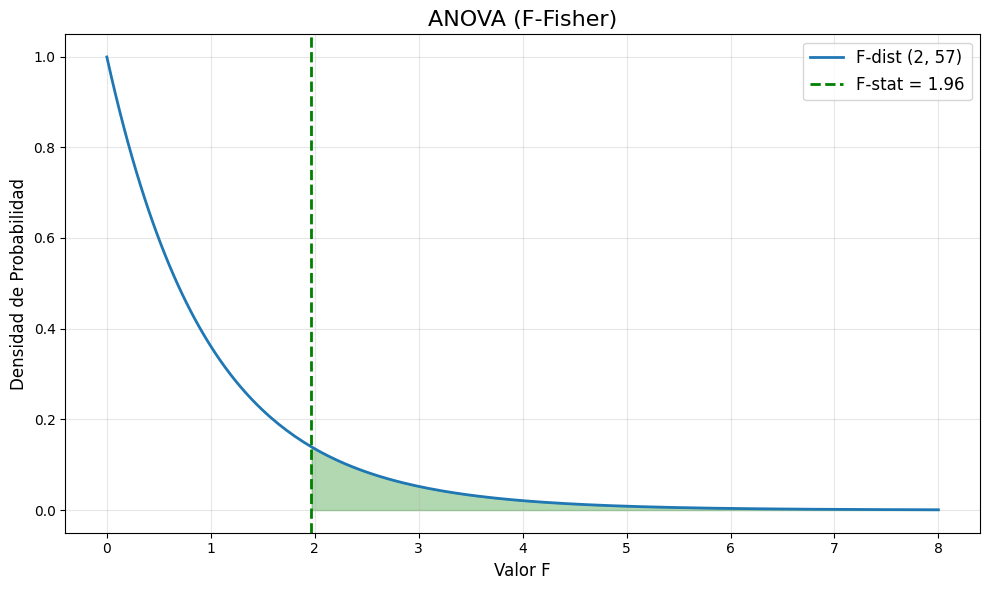

In [48]:
# Gráfico 2: ANOVA F
plt.figure(figsize=(10, 6))
x_f = np.linspace(0.001, 8, 200) # Empezamos en 0.001 y generamos 200 puntos para mayor suavidad
y_f = [pdf_f_fisher(val, df1_f, df2_f) for val in x_f]
plt.plot(x_f, y_f, label=f"F-dist ({df1_f}, {df2_f})", linewidth=2)
plt.axvline(f_stat, color='green', linestyle='--', linewidth=2, label=f"F-stat = {f_stat:.2f}")
plt.fill_between(x_f, y_f, where=(x_f >= f_stat), color='green', alpha=0.3)
plt.title("ANOVA (F-Fisher)", fontsize=16)
plt.xlabel("Valor F", fontsize=12)
plt.ylabel("Densidad de Probabilidad", fontsize=12)
# plt.ylim(bottom=0) # Opcional: asegura que el eje Y inferior empiece exactamente en 0
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

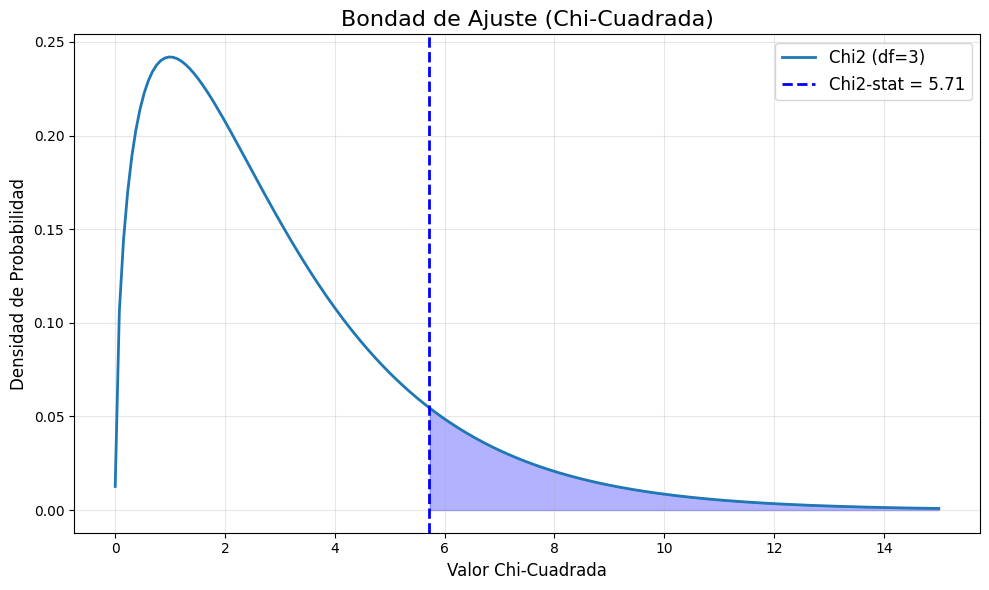

In [38]:
# Gráfico 3: Chi-Cuadrada
plt.figure(figsize=(10, 6))
x_c = np.linspace(0.001, 15, 200) # Empezamos en 0.001 para ver cómo nace la "campana" desde el origen
y_c = [pdf_chi2(val, df_chi) for val in x_c]
plt.plot(x_c, y_c, label=f"Chi2 (df={df_chi})", linewidth=2)
plt.axvline(chi_stat, color='blue', linestyle='--', linewidth=2, label=f"Chi2-stat = {chi_stat:.2f}")
plt.fill_between(x_c, y_c, where=(x_c >= chi_stat), color='blue', alpha=0.3)
plt.title("Bondad de Ajuste (Chi-Cuadrada)", fontsize=16)
plt.xlabel("Valor Chi-Cuadrada", fontsize=12)
plt.ylabel("Densidad de Probabilidad", fontsize=12)
# plt.ylim(bottom=0) # Opcional: asegura que el eje Y inferior empiece exactamente en 0
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()